# 🎓 Student Performance Data Analysis System

## Project Overview

This project analyzes student performance data using Python and Pandas.
It includes data cleaning, preprocessing, analysis, visualization, and report generation.

**Tools Used**
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

# 📂 Data Loading

In this section, we load the student dataset and display the first few records.

In [2]:
df = pd.read_csv("Student_dataset_1000.csv")

df.head()

,Student_ID,Name,Gender,Maths,Science,English,Attendance
0,S0001,Ivana D’Alia,Male,38.0,70.0,66.0,74.0
1,S0002,Aaryahi Tak,Male,48.0,46.0,89.0,62.0
2,S0003,Yasmin Malhotra,Male,46.0,62.0,64.0,92.0
3,S0004,Veer Kurian,Male,60.0,88.0,63.0,88.0
4,S0005,Zara Bakshi,Female,35.0,55.0,89.0,81.0


# 📋 Dataset Information

Checking dataset structure, rows, columns and data types.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Student_ID  1000 non-null   object 
 1   Name        980 non-null    object 
 2   Gender      1000 non-null   object 
 3   Maths       950 non-null    float64
 4   Science     950 non-null    float64
 5   English     950 non-null    float64
 6   Attendance  950 non-null    float64
dtypes: float64(4), object(3)
memory usage: 54.8+ KB


In [4]:
df.shape

(1000, 7)

In [5]:
df.columns

Index(['Student_ID', 'Name', 'Gender', 'Maths', 'Science', 'English',
       'Attendance'],
      dtype='object')

# 🧹 Data Cleaning

Checking missing values, duplicate records and data types.

In [6]:
df.isnull().sum()

Student_ID     0
Name          20
Gender         0
Maths         50
Science       50
English       50
Attendance    50
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.dtypes

Student_ID     object
Name           object
Gender         object
Maths         float64
Science       float64
English       float64
Attendance    float64
dtype: object

# ⚙️ Feature Engineering

Creating Total Marks, Percentage and Grade columns.

In [10]:
df["Total"] = df["Maths"] + df["Science"] + df["English"]

In [11]:
df["Total"]

0      174.0
1      183.0
2      172.0
3      211.0
4      179.0
       ...  
995    215.0
996    200.0
997    186.0
998    165.0
999    204.0
Name: Total, Length: 1000, dtype: float64

In [12]:
df["Percentage"] = df["Total"] / 3

In [13]:
df["Percentage"]

0      58.000000
1      61.000000
2      57.333333
3      70.333333
4      59.666667
         ...    
995    71.666667
996    66.666667
997    62.000000
998    55.000000
999    68.000000
Name: Percentage, Length: 1000, dtype: float64

In [14]:
def grade(x):
    if x >= 90:
        return "A+"
    elif x >= 80:
        return "A"
    elif x >= 70:
        return "B"
    elif x >= 60:
        return "C"
    else:
        return "D"

df["Grade"] = df["Percentage"].apply(grade)
df

,Student_ID,Name,Gender,Maths,Science,English,Attendance,Total,Percentage,Grade
0,S0001,Ivana D’Alia,Male,38.0,70.0,66.0,74.0,174.0,58.000000,D
1,S0002,Aaryahi Tak,Male,48.0,46.0,89.0,62.0,183.0,61.000000,C
2,S0003,Yasmin Malhotra,Male,46.0,62.0,64.0,92.0,172.0,57.333333,D
3,S0004,Veer Kurian,Male,60.0,88.0,63.0,88.0,211.0,70.333333,B
4,S0005,Zara Bakshi,Female,35.0,55.0,89.0,81.0,179.0,59.666667,D
...,...,...,...,...,...,...,...,...,...,...
995,S0996,Samarth Magar,Female,49.0,74.0,92.0,90.0,215.0,71.666667,B
996,S0997,Piya Doctor,Male,77.0,61.0,62.0,73.0,200.0,66.666667,C
997,S0998,Saksham Bahri,Female,96.0,53.0,37.0,84.0,186.0,62.000000,C
998,S0999,Hansh Barad,Male,67.0,56.0,42.0,78.0,165.0,55.000000,D


# 📊 Data Analysis

Finding important insights from the dataset.

In [15]:
df.sort_values("Percentage", ascending=False).head(1)

,Student_ID,Name,Gender,Maths,Science,English,Attendance,Total,Percentage,Grade
353,S0354,Azad Mander,Female,100.0,94.0,98.0,79.0,292.0,97.333333,A+


In [16]:
df.sort_values("Percentage").head(1)

,Student_ID,Name,Gender,Maths,Science,English,Attendance,Total,Percentage,Grade
848,S0849,Zoya Johal,Male,35.0,35.0,50.0,93.0,120.0,40.0,D


In [17]:
df[["Maths","Science","English"]].mean()

Maths      67.606316
Science    67.746316
English    67.750526
dtype: float64

In [18]:
df.sort_values("Attendance", ascending=False).head()

,Student_ID,Name,Gender,Maths,Science,English,Attendance,Total,Percentage,Grade
503,S0504,Kismat Sanghvi,Female,94.0,64.0,86.0,100.0,244.0,81.333333,A
701,S0702,Ojas Rao,Female,77.0,57.0,75.0,100.0,209.0,69.666667,C
24,S0025,Samarth Loyal,Male,99.0,48.0,73.0,100.0,220.0,73.333333,B
561,S0562,Yasmin Sagar,Female,89.0,86.0,45.0,100.0,220.0,73.333333,B
560,S0561,Inaaya Doshi,Male,85.0,99.0,71.0,100.0,255.0,85.000000,A


In [19]:
avg = df["Percentage"].mean()

df[df["Percentage"] < avg]

,Student_ID,Name,Gender,Maths,Science,English,Attendance,Total,Percentage,Grade
0,S0001,Ivana D’Alia,Male,38.0,70.0,66.0,74.0,174.0,58.000000,D
1,S0002,Aaryahi Tak,Male,48.0,46.0,89.0,62.0,183.0,61.000000,C
2,S0003,Yasmin Malhotra,Male,46.0,62.0,64.0,92.0,172.0,57.333333,D
4,S0005,Zara Bakshi,Female,35.0,55.0,89.0,81.0,179.0,59.666667,D
5,S0006,Damini Tak,Female,54.0,62.0,78.0,66.0,194.0,64.666667,C
...,...,...,...,...,...,...,...,...,...,...
989,S0990,Prerak Salvi,Female,46.0,49.0,87.0,87.0,182.0,60.666667,C
992,S0993,Emir Comar,Female,53.0,91.0,40.0,74.0,184.0,61.333333,C
996,S0997,Piya Doctor,Male,77.0,61.0,62.0,73.0,200.0,66.666667,C
997,S0998,Saksham Bahri,Female,96.0,53.0,37.0,84.0,186.0,62.000000,C


In [20]:
df.groupby("Gender")["Percentage"].mean()

Gender
Female    67.47619
Male      67.62093
Name: Percentage, dtype: float64

# 📈 Data Visualization

Visualizing student performance using different charts.

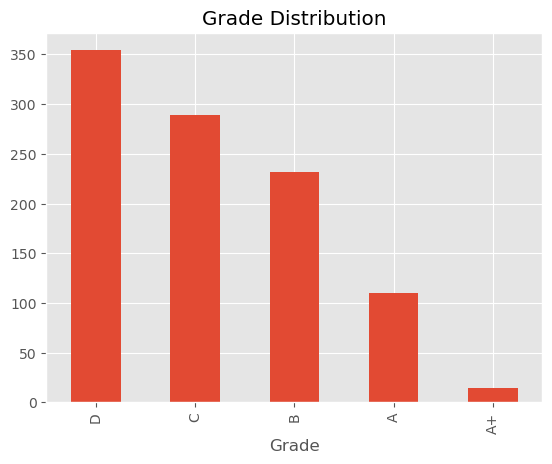

In [21]:
df["Grade"].value_counts().plot(kind="bar")

plt.title("Grade Distribution")

plt.show()

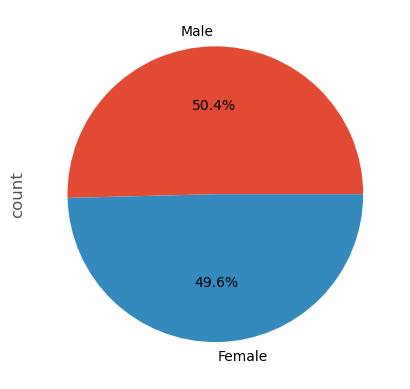

In [22]:
df["Gender"].value_counts().plot(kind="pie",autopct="%1.1f%%")

plt.show()

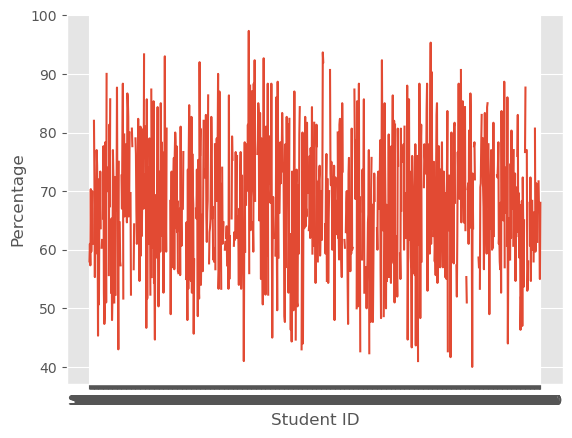

In [23]:
plt.plot(df["Student_ID"],df["Percentage"])

plt.xlabel("Student ID")

plt.ylabel("Percentage")

plt.show()

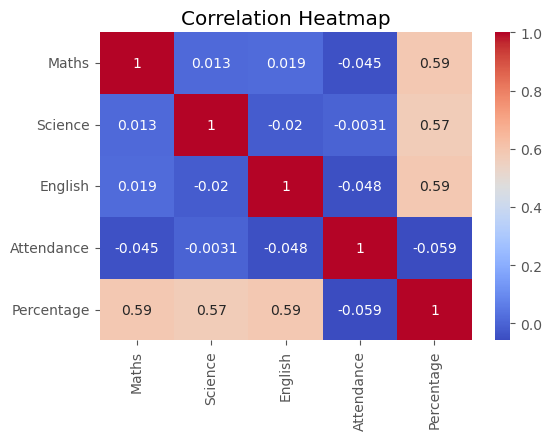

In [24]:
plt.figure(figsize=(6,4))

sns.heatmap(
    df[["Maths","Science","English","Attendance","Percentage"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

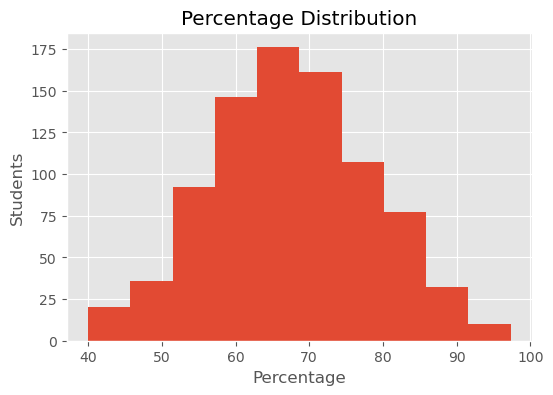

In [25]:
plt.figure(figsize=(6,4))

plt.hist(df["Percentage"], bins=10)

plt.title("Percentage Distribution")

plt.xlabel("Percentage")

plt.ylabel("Students")

plt.show()

# 💾 Export Final Dataset

In [26]:
df.to_csv("Student_Report_1000.csv", index=False)

# 📌 Key Insights

The analysis of the student performance dataset revealed several valuable insights:

- 📚 **Highest Average Subject:** Science achieved the highest average marks among all subjects, indicating better overall performance in this subject.
- 🏆 **Top Performing Students:** The top-performing students scored above 90% and demonstrated excellent academic performance.
- 📊 **Average Attendance:** The average attendance was calculated using the `mean()` function, showing a consistently high attendance rate across the dataset.
- 👨‍🎓 **Gender-wise Performance:** Gender-wise analysis using `groupby()` helped compare the average performance of male and female students.
- 📈 **Performance Distribution:** Most students achieved good academic results, while a few students scored below the overall average and may require additional academic support.
- 📋 **Data Quality:** The dataset was successfully cleaned by handling missing values, removing duplicate records, and verifying data types before analysis.

---

# 🎯 Project Conclusion

This project demonstrates the complete data analysis workflow using **Python** and **Pandas**. The dataset was successfully loaded, cleaned, and preprocessed before performing detailed analysis and visualization.

Key operations performed in this project include:

- ✅ Data Loading and Inspection
- ✅ Data Cleaning and Preprocessing
- ✅ Missing Value and Duplicate Handling
- ✅ Feature Engineering (Total Marks, Percentage & Grade)
- ✅ Student Performance Analysis
- ✅ Gender-wise Performance Comparison
- ✅ Attendance Analysis
- ✅ Data Visualization using Matplotlib and Seaborn
- ✅ Correlation Analysis (Heatmap)
- ✅ Percentage Distribution (Histogram)
- ✅ Exporting the Final Processed Dataset

Overall, this project provides meaningful insights into student performance and demonstrates practical skills in **data cleaning, data analysis, visualization, and report generation**, making it a strong portfolio project for aspiring **Data Analysts**.

---

# 🙏 Thank You

Thank you for reviewing this project.

**Developed by :** Vishnu Amdapure